In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, ConfusionMatrixDisplay)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

In [11]:
# 1. Data acquisition
dataset = load_breast_cancer(as_frame=True)
df = dataset.frame.copy()
df = df.rename(columns={"target": "diagnosis_target"})
# sklearn target: 0 = malignant, 1 = benign
df["diagnosis"] = df["diagnosis_target"].map({0: "malignant", 1: "benign"})
print("Shape:", df.shape)
print("Columns:", len(df.columns))
print("Missing values before cleaning:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

Shape: (569, 32)
Columns: 32
Missing values before cleaning: 0
Duplicate rows: 0


In [12]:
# 2. Cleaning / quality checks
df = df.drop_duplicates().reset_index(drop=True)
feature_cols = list(dataset.feature_names)
X = df[feature_cols]
y = df["diagnosis_target"]
# Median imputation is included in the model pipeline so missing values are handled safely.
print("\nClass counts:\n", df["diagnosis"].value_counts())


Class counts:
 diagnosis
benign       357
malignant    212
Name: count, dtype: int64


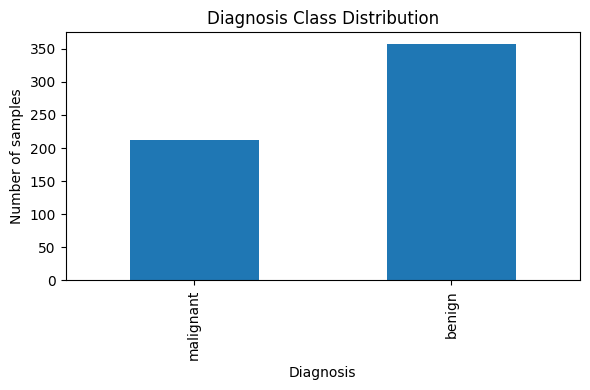


Selected feature summary:
        mean radius  mean texture  mean perimeter  mean area  mean smoothness
count       569.00        569.00          569.00     569.00           569.00
mean         14.13         19.29           91.97     654.89             0.10
std           3.52          4.30           24.30     351.91             0.01
min           6.98          9.71           43.79     143.50             0.05
25%          11.70         16.17           75.17     420.30             0.09
50%          13.37         18.84           86.24     551.10             0.10
75%          15.78         21.80          104.10     782.70             0.11
max          28.11         39.28          188.50    2501.00             0.16


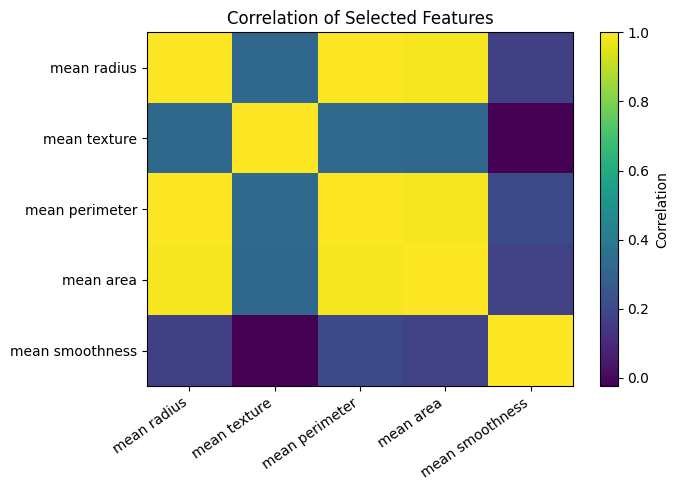

In [13]:
# 3. EDA visualizations
plt.figure(figsize=(6, 4))
df["diagnosis"].value_counts().reindex(["malignant", "benign"]).plot(kind="bar")
plt.title("Diagnosis Class Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of samples")
plt.tight_layout()
plt.savefig("week6_class_distribution.png", dpi=160)
plt.show()

selected = ["mean radius", "mean texture", "mean perimeter", "mean area", "mean smoothness"]
print("\nSelected feature summary:\n", df[selected].describe().round(2))
corr = df[selected].corr()
plt.figure(figsize=(7, 5))
plt.imshow(corr, aspect="auto")
plt.xticks(range(len(selected)), selected, rotation=35, ha="right")
plt.yticks(range(len(selected)), selected)
plt.colorbar(label="Correlation")
plt.title("Correlation of Selected Features")
plt.tight_layout()
plt.savefig("week6_feature_correlation.png", dpi=160)
plt.show()



5-fold CV accuracy: 0.9560 +/- 0.0120
Test accuracy: 0.9474
Test precision (malignant label=0): 0.9286
Test recall (malignant label=0): 0.9286
Test F1 (malignant label=0): 0.9286

Classification report:
               precision    recall  f1-score   support

   malignant       0.93      0.93      0.93        42
      benign       0.96      0.96      0.96        72

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



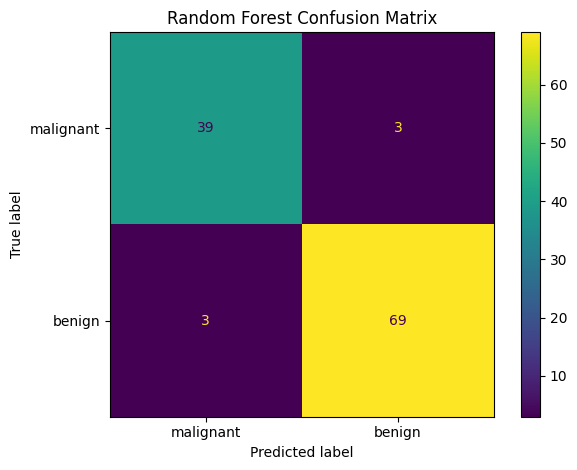

In [14]:
# 4. Supervised model: Random Forest classification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
classifier = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(n_estimators=300, random_state=42,
                                     class_weight="balanced"))
])
cv_scores = cross_val_score(classifier, X_train, y_train, cv=5, scoring="accuracy")
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)
print("\n5-fold CV accuracy: %.4f +/- %.4f" % (cv_scores.mean(), cv_scores.std()))
print("Test accuracy: %.4f" % accuracy_score(y_test, y_pred))
print("Test precision (malignant label=0): %.4f" %
      precision_score(y_test, y_pred, pos_label=0, zero_division=0))
print("Test recall (malignant label=0): %.4f" %
      recall_score(y_test, y_pred, pos_label=0, zero_division=0))
print("Test F1 (malignant label=0): %.4f" %
      f1_score(y_test, y_pred, pos_label=0, zero_division=0))
print("\nClassification report:\n",
      classification_report(y_test, y_pred, target_names=dataset.target_names))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=dataset.target_names, cmap=None
)
plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.savefig("week6_confusion_matrix.png", dpi=160)
plt.show()



Silhouette scores by k: {2: np.float64(0.34338224069077805), 3: np.float64(0.3143840098608098), 4: np.float64(0.28330544840954164), 5: np.float64(0.15821041754355697)}
Selected k: 2
Cluster counts:
 cluster
0    375
1    194
Name: count, dtype: int64

Cluster means (selected features):
          mean radius  mean texture  mean perimeter  mean area  mean smoothness
cluster                                                                       
0              12.43         18.26           79.82     486.77             0.09
1              17.41         21.28          115.45     979.86             0.10


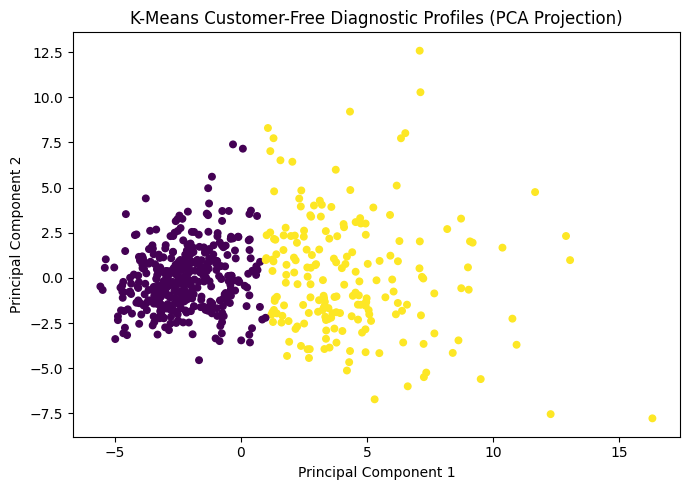

In [15]:
# 5. Unsupervised learning: K-Means clustering
# Scale continuous measurements before clustering.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
# Compare k=2..5 using silhouette score; choose best score among candidates.
silhouette_results = {}
for k in range(2, 6):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    silhouette_results[k] = silhouette_score(X_scaled, labels)
best_k = max(silhouette_results, key=silhouette_results.get)
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_scaled)
df["cluster"] = cluster_labels
print("\nSilhouette scores by k:", silhouette_results)
print("Selected k:", best_k)
print("Cluster counts:\n", df["cluster"].value_counts().sort_index())
print("\nCluster means (selected features):\n",
      df.groupby("cluster")[selected].mean().round(2))

# PCA plot for 2D visualization (clusters are fitted in original scaled feature space).
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
plt.figure(figsize=(7, 5))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, s=22)
plt.title("K-Means Customer-Free Diagnostic Profiles (PCA Projection)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.savefig("week6_cluster_pca.png", dpi=160)
plt.show()


Top 10 feature importances:
 worst perimeter         0.1451
worst area              0.1390
worst concave points    0.1097
mean concave points     0.0965
worst radius            0.0786
mean radius             0.0498
mean concavity          0.0498
worst concavity         0.0436
mean perimeter          0.0425
area error              0.0388
dtype: float64


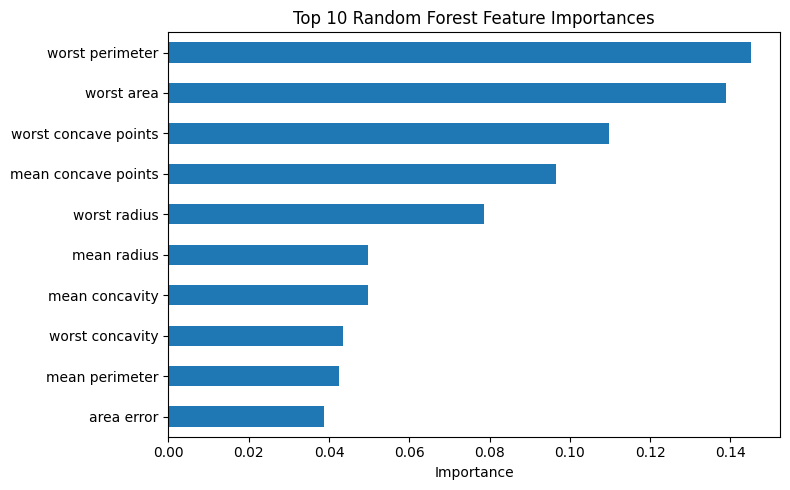

In [16]:
# 6. Feature importance (model interpretation)
rf = classifier.named_steps["model"]
importance = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False).head(10)
print("\nTop 10 feature importances:\n", importance.round(4))
plt.figure(figsize=(8, 5))
importance.sort_values().plot(kind="barh")
plt.title("Top 10 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("week6_feature_importance.png", dpi=160)
plt.show()

In [17]:
# 7. Save a copy of the analyzed dataset
df.to_csv("week6_capstone_analyzed_data.csv", index=False)
print("\nSaved: week6_capstone_analyzed_data.csv and visualization PNG files.")
print("Reminder: educational demonstration only; not for clinical use.")



Saved: week6_capstone_analyzed_data.csv and visualization PNG files.
Reminder: educational demonstration only; not for clinical use.
